### **Maestría en Inteligencia Artificial Aplicada**

###**Curso: Inteligencia Artificial y Aprendizaje Automático**

**Tecnológico de Monterrey**

Prof Luis Eduardo Falcón Morales

### **Actividad de la Semana: Problema de Clasificación con Datos Desbalanceados : Oil-Spill**

* **Nombre: Lizbeth Celeste Duron Escareño**

* **Matrícula: A01748476**

# **Introducción**

* La actividad se basa en los datos conocidos como "oil-spill" (derrame de petróleo).

* En la web puedes encontrar varias referencias a este mismo problema, pero en donde el archivo de datos no es exactamente igual. Por ello y para asegurar que el conjunto de datos con el que estaremos trabajando es el mismo para todos, dicho archivo lo encontrarás en Canvas.

* El archivo con los datos de esta actividad lo encuentras en Canvas con el nombre "oil-spill.csv".

* En la siguiente liga se encuentra el artículo original relacionado a dicha base de datos:

https://webdocs.cs.ualberta.ca/~holte/Publications/oilspill.pdf

* De dicho artículo sabemos que los datos incluyen 50 columnas y 937 registros. Las primeras 49 columnas son métricas obtenidas de imágenes satelitales del océano, en algunas de las cuales se tiene petróleo que fue derramado por alguna fuente desconocida. En el artículo se describe a detalle la manera en que se obtuvieron dichas columnas. Para la presente actividad es suficiente con saber que dichos valores numéricos son información valiosa que nos permiten entender lo qu hay en la imagen, en particular, el ayudar a distinguir si hay o no derramamiento de combustible en dicha imagen.

* La última columna llamada "target" puede tomar el valor de 1 (hay derrame en ese pedazo de la imagen) o 0 (no hay derrame en ese pedazo de la imagen).

* Así, por el momento es suficiente con que consideres que cada una de las primeras 49 columnas son variables de tipo numérico continua y la última es de valor binario, en este problema de clasificación.

* En un curso posterior de visión computacional dentro de la maestría podrás estudiar técnicas para extraer dicha información numérica de las imágenes, en caso de que este tema sea de tu interés.

* Para fines de esta actividad usaremos la librería llamada "imbalanced-learn", usada comunmente en problemas de clases desbalanceadas. En particular, usaremos el siguiente método que nos proporciona un reporte con los valores de varias métricas utilizadas comunmente en problemas de clases desbalanceadas:

https://imbalanced-learn.org/stable/references/generated/imblearn.metrics.classification_report_imbalanced.html

In [2]:
# Incluye a continuación todas librerías que consideres necesarias:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split





**NOTAS:**

* **Para fines de esta actividad, pre-procesaremos los datos de manera genérica para poder concentrarnos en los temas relacionados al curso.**

* **Siempre podrás regresar en el futuro y trabajar de mejor manera el pre-procesamiento de los datos.**

In [3]:
# Cargamos los datos del archivo de la actividad:
path ='oil_spill.csv'
df = pd.read_csv(path)

# Eliminamos las siguientes columnas:
#   - f_1 contiene información de secciones (batches) de las imágenes que no requerimos para esta actividad.
#   - f_23 tiene un solo valor constante.
df.drop("f_1", axis=1, inplace=True)
df.drop("f_23", axis=1, inplace=True)

# Despleguemos los primeros valores:
print('Dimensión del DataFrame',df.shape)
df.head(4).T


Dimensión del DataFrame (937, 48)


,0,1,2,3
f_2,2558.00,22325.00,115.00,1201.00
f_3,1506.09,79.11,1449.85,1562.53
f_4,456.63,841.03,608.43,295.65
f_5,90.00,180.00,88.00,66.00
f_6,6395000.00,55812500.00,287500.00,3002500.00
f_7,40.88,51.11,40.42,42.40
f_8,7.89,1.21,7.34,7.97
f_9,29780.00,61900.00,3340.00,18030.00
f_10,0.19,0.02,0.18,0.19
f_11,214.70,901.70,86.10,166.50


In [4]:
# Particionamos los datos de entrada (X) y de salida (y):
X,y = df.iloc[:,:-1], df.iloc[:,-1]

# Utilizamos las semillas indicadas para la reproducibilidad de los resultados de la actividad:
Xtv, Xtest, ytv, ytest = train_test_split(X, y, test_size=0.12, stratify=y, shuffle=True, random_state=1)
Xtrain, Xval, ytrain, yval = train_test_split(Xtv, ytv, test_size=0.2, shuffle=True, random_state=7)


# Veamos que tenemos un problema de clases bastante desbalanceadas.
# Para ello mostremos la distribución de los conjuntos de entrenamiento, validación y prueba.
# En realidad, solo deberíamos mostrar los valores del conjunto de entrenamiento
# para evitar el problema del filtrado de información (data leakage). Sin embargo,
# con fines meramente euducativos, mostramos también la distribución de los conjuntos
# de validación (val) y de prueba (test), para darnos una idea de la complejidad del
# problema y del reto que tenemos para entrenar un buen modelo de clasificación.
# Es decir, tenemos una cantidad muy pequeña de datos de la clase positiva
# en el conjunto de validación y en el de prueba y aún así, deberemos
# hacer el esfuerzo para diseñar un buen modelo que distinga estos pocos datos.

print('\nPartición de los conjuntos de Entrenamiento, Validación y Prueba:')
print('+'*70)
tmp = 100 * (ytrain.sum() / len(ytrain))
print('Train:')
print('Conteo_clase_positiva= %d (%.2f%%)' % (ytrain.sum(), tmp))
print('Conteo_clase_negativa= %d (%.2f%%)' % ((len(ytrain)-ytrain.sum()), 100-tmp))

print('\nValidation:')
tmp = 100 * (yval.sum() / len(yval))
print('Conteo_clase_positiva= %d (%.2f%%)' % (yval.sum(), tmp))
print('Conteo_clase_negativa= %d (%.2f%%)' % ((len(yval)-yval.sum()), 100-tmp))

print('\nTest:')
tmp = 100 * (ytest.sum() / len(ytest))
print('Conteo_clase_positiva= %d (%.2f%%)' % (ytest.sum(), tmp))
print('Conteo_clase_negativa= %d (%.2f%%)' % ((len(ytest)-ytest.sum()), 100-tmp))


Partición de los conjuntos de Entrenamiento, Validación y Prueba:
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
Train:
Conteo_clase_positiva= 28 (4.25%)
Conteo_clase_negativa= 631 (95.75%)

Validation:
Conteo_clase_positiva= 8 (4.85%)
Conteo_clase_negativa= 157 (95.15%)

Test:
Conteo_clase_positiva= 5 (4.42%)
Conteo_clase_negativa= 108 (95.58%)


# **Ejercicio-1**

### **Consideremos en primer instancia que los errores de falsos poitivos y falsos negativos son igualmente costosos. Y ya que tenemos un problema bastante desbalanceado, usaremos la media geométrica como métrica principal para buscar el mejor modelo. A partir de esta información, responde las siguientes preguntas:**

* ### **a) En el contexto de este problema del derrame de petróleo, ¿cómo justificas el no utilizar la métrica de la exactitud (accuracy), y sí utlizar la métrica G_mean?**

* ### **b) En el contexto del problema ¿qué significa un Falso Positivo y cuáles podrían ser algunas de sus implicaciones al cometer uno de estos errores?**

* ### **c) En el contexto del problema ¿qué significa un Falso Negativo y cuáles podrían ser algunas de sus implicaciones al cometer uno de estos errores?**





Respuestas Ejercicio-1:


* 1a) La accurancy está dominada por la clase mayoritaría, por lo que oculta el mal desempeño sobre la clase minoritaría. G_mean obliga a encontrar un equilibrio entre detectar derrames y no dar falsas alarmas.

* 1b) Un falso positivo ocurre cuando el modelo predice que "hay derrame" cuando en realidad no lo hay. Las implicaciones que puede haber son costo operativo, desperdicio de recursos, fatiga de alarmas, posibles repercusiones legales o repercusiones legales o reputacionales, etc.

* 1c) Un falsho negativo es cuando el modelo predice que no hay derrame cuando realmente si existe un derrame real. Las implicaciones son daño ambiental, mayor costo de remediación, impacto económico y social, responsabilidad legal y regulatoria, etc.

* **Incluyamos a continuación una breve descripción numérica y gráfica del conjunto de entrenamiento. Es lo mínimo en cuanto a pre-procesamiento que haremos. Más adelante puedes regresar y realizar un mayor análisis.**

* **En dado caso, puedes incluir más celdas con análisis adicionales, si así lo deseas.**

In [5]:
Xtrain.describe().T

,count,mean,std,min,25%,50%,75%,max
f_2,659.0,350.377845,1.911459e+03,10.00,19.000,63.00,134.000,28526.00
f_3,659.0,692.040516,6.013521e+02,1.92,83.905,646.26,1229.325,1789.13
f_4,659.0,853.822398,5.259526e+02,1.00,435.500,719.81,1238.040,2724.57
f_5,659.0,85.613050,4.564260e+01,0.00,54.000,74.00,120.500,180.00
f_6,659.0,831366.966616,4.158159e+06,71718.00,125000.000,185000.00,337500.000,71315000.00
f_7,659.0,43.517132,1.287405e+01,21.24,33.760,40.35,53.090,82.64
f_8,659.0,9.244294,3.590490e+00,1.21,6.935,8.33,11.045,23.47
f_9,659.0,4094.624431,8.960913e+03,704.00,1332.000,2100.00,3445.000,160740.00
f_10,659.0,0.221730,8.687786e-02,0.02,0.170,0.21,0.260,0.67
f_11,659.0,110.794537,6.187135e+01,41.00,84.400,100.10,116.300,901.70


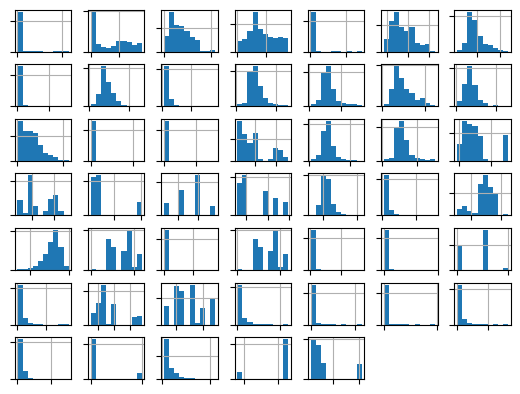

In [6]:
# Histogramas:
ax = Xtrain.hist()
# Quitemos toda la información del gráfico para visualizarlos de manera sencilla:
for axis in ax.flatten():
  axis.set_title('')
  axis.set_xticklabels([])
  axis.set_yticklabels([])
plt.show()



In [7]:
Xtrain.info()

<class 'pandas.core.frame.DataFrame'>
Index: 659 entries, 433 to 625
Data columns (total 47 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   f_2     659 non-null    int64  
 1   f_3     659 non-null    float64
 2   f_4     659 non-null    float64
 3   f_5     659 non-null    int64  
 4   f_6     659 non-null    float64
 5   f_7     659 non-null    float64
 6   f_8     659 non-null    float64
 7   f_9     659 non-null    float64
 8   f_10    659 non-null    float64
 9   f_11    659 non-null    float64
 10  f_12    659 non-null    float64
 11  f_13    659 non-null    float64
 12  f_14    659 non-null    float64
 13  f_15    659 non-null    float64
 14  f_16    659 non-null    float64
 15  f_17    659 non-null    float64
 16  f_18    659 non-null    float64
 17  f_19    659 non-null    float64
 18  f_20    659 non-null    float64
 19  f_21    659 non-null    float64
 20  f_22    659 non-null    float64
 21  f_24    659 non-null    float64
 22  f_25 

**En resumen:**

* De lo anterior observamos que:
  * Todos los valores ya son numéricos, positivos, negativos o cero.
  * No hay datos perdidios.
  * La diferencia de escala entre todos los factores es muy diversa y la distribución de las variables también es muy variada.

* **Como una primera aproximación transformaremos todos los factores con la Yeo-Johnson para corregir un poco el sesgo de las distribuciones que suele afectar en general a los modelos como la regresión logística y luego los escalaremos para ayudar a que todos los factores estén en iguales condiciones de mostrar su importancia.**

# **Ejercicio-2**

### **En relación a la transformación Yeo-Johnson, investiga:**

* ### **a) ¿En qué consiste dicha transformación?**

* ### **b) ¿Cuál es su diferencia con la transformación Box-Cox?**


Respuestas Ejercicio-2:


* 2a) La transformación Yeo-Johnson es una transformación de potencia que aplica una unción distinta a cada variable para que su distribución se parezca más a una normal: reduce el sesgo (asimetría) y estabiliza la varianza.

* 2b) La diferencia principal es el dominio de los datos. Box-Cox solo funciona con valores estrictamente positivos. Con ceros o negativos, la potencia o el logaritmo no están definidos.Yeo-Johnson es una extensión que admite positivos, ceros y negativos.

In [10]:
# Transformaciones numéricas evitando el filtrado de información:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.compose import ColumnTransformer

numericas_pipeline = Pipeline(steps = [('impMediana', SimpleImputer(strategy='mean')),
                                       ('yeo-johnson', PowerTransformer(method='yeo-johnson')),
                                       ('std_transformer', StandardScaler()),
                                       ])

numericas_pipeline_nombres = Xtrain.columns

columnasTransformer = ColumnTransformer(transformers = [('num', numericas_pipeline, numericas_pipeline_nombres)],
                                        remainder='passthrough')


# **Ejercicio-3**

### **En este ejercicio deberás obtener el valor de umbral del modelo base (baseline) con el conjunto de entrenamiento, que nos ayude a determinar si un modelo está subentrenado.**

* ### **a) Encuentra la estrategia (strategy) del DummyClassifier más adecuada. Además, selecciona el número de divisiones (n_splits) de RepeatedStratifiedKFold que consideres sea el más adecuado para particionar en los conjuntos de entrenamiento y validación al aplicar validación cruzada con el modelo DummyClassifier. Prueba varios valores y observa el resultado de la media y desviación estándar antes de hacer tu mejor selección. Responde a continuación cómo llegaste a decidirte por valor que seleccionaste.**

* ### **b) Con base a tu mejor decisión para "strategy" y "n_splits", ¿cuál es el valor que se usará para determinar si un modelo está subentrenado, al usar la métrica G_mean?**

* ### **c) Si utilizáramos la métrica de la exactitud (accuracy) en este problema del derrame del petróleo, ¿cuál sería el valor de umbral del modelo base a superar? Incluye además la matriz de confusión de este modelo ingenuo con la métrica de la exactitud.**

Respuestas Ejercicio-3:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++


* 3a) most_frequent, prior y constant predicen siempre la misma clase. Eso da una sensibilidad de 0, la G-mean es 0 con desviación 0. La estrategia stratified predice al azar respetando la proporción de clases del entrenamiento. Uniform ignora el desbalance y no es una referencia realista aquí. Por eso la mejor opción es stratified.
Con n_splits de 5 y n_repeats de 10 o más se estabilizaría la media. Se escoge este valor ya que se busva un valor en donde a desviación estándar sea razonable y la media no cambie mucho respecto a los vecinos.

* 3b) Con stratified, la sensibilidad esperada es 0.044 y la especificidad 0.956, así que G-mean es 0.2. Un modelo con G-mean menor o igual a ese valor está subentrenado.

* 3c) Para accuracy, el modelo ingenuo es most_frequent (siempre predice la clase mayoritaria, “sin derrame”). Su exactitud es aproximadamente 0.956. Cualquier modelo útil debe superar ese valor, aunque ese número es engañoso: un modelo que nunca detecta un derrame ya logra casi 96 %.


In [13]:
#matriz de confusión
from sklearn.dummy import DummyClassifier
from sklearn.metrics import confusion_matrix

dummy = DummyClassifier(strategy='most_frequent').fit(Xtrain, ytrain)
pred = dummy.predict(Xtrain)
print("Accuracy:", dummy.score(Xtrain, ytrain))
print(confusion_matrix(ytrain, pred))

Accuracy: 0.9575113808801214
[[631   0]
 [ 28   0]]


NOTA: Recuerda revisar la documentación correspondiente de sklearn para la selección adecuada de los argumentos:

* DummyClassifier:

https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html

* RepeatedStratifiedKFold:

https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RepeatedStratifiedKFold.html

In [15]:
# Definamos una variable con la métrica G-mean a utilizar en los modelos:
from sklearn.metrics import make_scorer
from imblearn.metrics import geometric_mean_score
mi_metrica = make_scorer(geometric_mean_score)


In [20]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from numpy import mean, std
# Utilicemos la función DummyClassifier de sklearn con la métrica G-mean para
# obtener el desempeño del modelo base (baseline).

# Usa esta celda para probar diferentes valores de "strategy" y "n_splits".
# Con base a los resultados observados selecciona tus mejores opciones y
# responde a las preguntas de los incisos anteriores del Ejercicio-3.


# ----------------- Incluye a continuación tus mejores opciones -----------

mi_estrategia = 'stratified'

mi_nsplits = 5


# ----------------- Fin para realizar ajustes -----------------------------



# No modifiques las semillas.
cv = RepeatedStratifiedKFold(n_splits=mi_nsplits, n_repeats=3, random_state=7)  # Validación Cruzada Estratificada.
modeloD = DummyClassifier(strategy=mi_estrategia, random_state=7)
pipelineD = Pipeline(steps=[('ct',columnasTransformer),('Dummy',modeloD)])
scores = cross_val_score(pipelineD, Xtrain, ytrain, scoring=mi_metrica, cv=cv, n_jobs=-1)  # Cuidamos el filtrado de información.

print('Veamos los desempeños obtenidos con la DummyClassifier y la métrica G-mean.')
print('Imprimimos los resultados de todas las secciones (folds) generadas con Validación-Cruzada:')
print('+'*90)
print(scores)


print('\nObtenemos el valor promedio y desviación estandar (std) de dichos resultados:')
print('+'*80)
print('Promedio de los desempeños con la G-mean[Media Geométrica]=%.3f, std=(%.3f)' % (mean(scores), std(scores)))


Veamos los desempeños obtenidos con la DummyClassifier y la métrica G-mean.
Imprimimos los resultados de todas las secciones (folds) generadas con Validación-Cruzada:
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
[0.         0.         0.         0.         0.         0.
 0.         0.40499526 0.         0.         0.         0.
 0.         0.40499526 0.        ]

Obtenemos el valor promedio y desviación estandar (std) de dichos resultados:
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
Promedio de los desempeños con la G-mean[Media Geométrica]=0.054, std=(0.138)


# **Ejercicio-4**

* ### **Ya que tenemos las referencias de los modelos base (baseline) o ingenuo (naive) para las métricas de exactitud (accuracy) y G-mean. Ejecuta a continuación la siguiente celda. Observa que estaremos ejecutando los modelos con el mínimo de ajuste de los valores predeterminados de los hiperparámetros. Esto con el objetivo de tener un punto de partida sobre qué tan alejados estamos de obtener buenos modelos. Sirve también como ejemplo para mostrar cómo se  desempeñan los modelos cuando se ejecutan con sus valores predeterminados, que en muchas ocasiones son los resultados que muestran algunos LLM (modelos grandes de lenguaje). Esto nos muestra que no porque no tengamos errores de ejecución o compilación, no significa que ya alcanzamos el objetivo buscado.**

* ### **Observa que estamos usando los conjuntos Xtv y ytv para entrenar los modelos ya que estamos utilizando validación cruzada y además, mostramos al inicio que tenemos muy pocos datos de la clase positiva minoritaria en el conjunto de validación.**

Resultados de Validación:
LR
Exactitud: >> 0.947 (0.015)
G-mean: >> 0.654 (0.119)

LASSO
Exactitud: >> 0.960 (0.009)
G-mean: >> 0.501 (0.158)

RIDGE
Exactitud: >> 0.959 (0.008)
G-mean: >> 0.541 (0.113)

EN
Exactitud: >> 0.960 (0.007)
G-mean: >> 0.540 (0.109)

kNN
Exactitud: >> 0.956 (0.006)
G-mean: >> 0.174 (0.187)



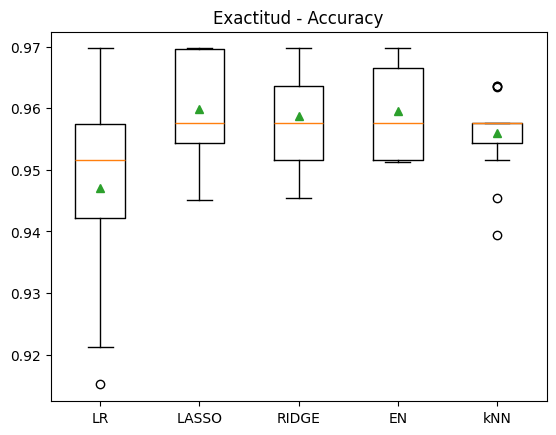

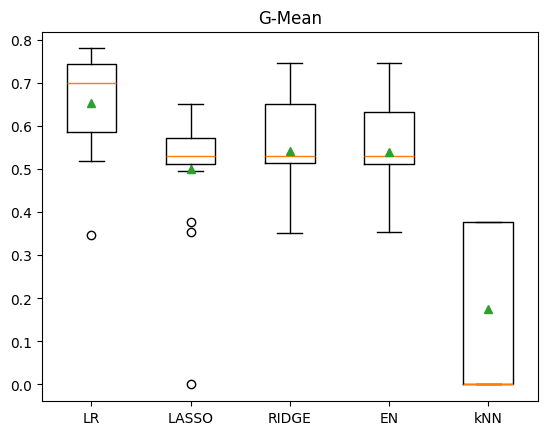

In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_validate
# Código-1:

# Ejecuta esta celda sin modificaciones.

# Estamos ejecutando los modelos con el mínimo de ajustes para usar sus valores predetermiandos
# y mostrando los desempeños con las métricas de exactitud (accuracy) y G-mean.

# Definimos primeramente los modelos a entrenar y evaluar:

def mis_modelos1():
  modelos, nombres = list(), list()

  modelos.append(LogisticRegression(penalty=None, # Este valor del argumento define el modelo sin regularización.
                                    max_iter=2000,
                                    random_state=1))
  nombres.append('LR')


  modelos.append(LogisticRegression(penalty='l1',  # modelo Lasso o de métrica L1.
                                    solver='liblinear',
                                    max_iter=2000,
                                    random_state=1))
  nombres.append('LASSO')


  modelos.append(LogisticRegression(penalty='l2',   # modelo Ridge o de métrica L2.
                                    max_iter=2000,
                                    random_state=1))
  nombres.append('RIDGE')

  modelos.append(LogisticRegression(penalty='elasticnet',  # modelo Elastic-Net o de métrica L1-L2.
                                    l1_ratio=0.5,
                                    solver='saga',
                                    max_iter=5000,
                                    random_state=1))
  nombres.append('EN')

  modelos.append(KNeighborsClassifier(n_neighbors=5))
  nombres.append('kNN')

  return modelos, nombres

# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++


modelos, nombres = mis_modelos1()
resultados1, resultados2 = list(), list()
print('Resultados de Validación:')

for i in range(len(modelos)):

  pipeline = Pipeline(steps=[('ct',columnasTransformer),('m',modelos[i])])
  cv1 = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)
  scores = cross_validate(pipeline,
                          Xtv,
                          np.ravel(ytv),
                          scoring={'exactitud':'accuracy', 'm_geo':mi_metrica},
                          cv=cv1)

  resultados1.append(scores['test_exactitud'])
  resultados2.append(scores['test_m_geo'])

  print(nombres[i])
  print('Exactitud: >> %.3f (%.3f)' % (np.nanmean(scores['test_exactitud']), np.nanstd(scores['test_exactitud'])))
  print('G-mean: >> %.3f (%.3f)' % (np.nanmean(scores['test_m_geo']), np.nanstd(scores['test_m_geo'])))
  print()

plt.boxplot(resultados1, tick_labels=nombres,  showmeans=True)
plt.title("Exactitud - Accuracy")
plt.show()

plt.boxplot(resultados2, tick_labels=nombres,  showmeans=True)
plt.title("G-Mean")
plt.show()




### **Habiendo ejecutado la celda anterior sin ajustar hiperparámetros, responde lo siguiente:**

### **4a) ¿Cuáles modelos están subentrenados con respecto a la métrica de la exactitud (accuracy)?**

### **4b) ¿Cuáles modelos están subentrenados con respecto a la métrica de la media geométrica (G-mean)?**



* 4a) Subentrenados LR y kNN. LR queda por debajo del modelo ingenuo y kNN solo lo iguala.

* 4b) Subentrenado solo kNN.


# **Ejercicio-5**

* ### **Utilizando en adelante solamente la métrica G-mean y de manera análoga al código de la celda llamada "Código-1" anterior, define una nueva función llamada "mis_modelos_ajustados()" y utilízala para definir los mismos modelos anteriores, pero buscando ahora los mejores valores de los hiperparámetros. Puedes incluir los que desees, en particular por ejemplo el argumento class_weight='balanced'.**

* ### **La salida no deberá mostrar errores o advertencias (warnings).**

* ### **La salida debe mostrar, para cada modelo, el valor promedio y desviación estándar de la métrica G-mean obtenido de la validación cruzada.**

* ### **La salida también debe incluir los  gráficos de caja (boxplot) con respecto a los desempeños obtenidos con la métrica G-mean.**


* ### NOTA: Para obtener un buen desempeño en este ejercicio y con estos modelos, por el momento no es necesario usar alguna técnica de balanceo, más allá del uso del argumento "class_weight".

Resultados de los modelos ajustados con la métrica G-mean
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
Resultados de Validación (G-mean):
LR
G-mean: >> 0.754 (0.120)

LASSO
G-mean: >> 0.849 (0.042)

RIDGE
G-mean: >> 0.817 (0.106)

EN
G-mean: >> 0.824 (0.070)

kNN
G-mean: >> 0.199 (0.186)



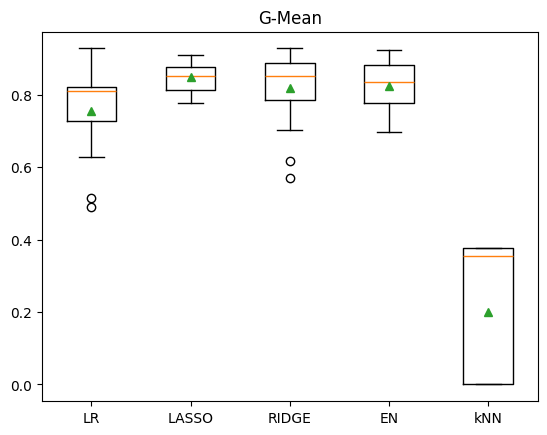

In [23]:
# 5)



print('Resultados de los modelos ajustados con la métrica G-mean')
print('+'*80)

# ++++++++++ Inicia sección para agregar tu código ++++++++++++++++++++++++
# NOTA: puedes agregar todas las celdas que consideres adecuado.



import warnings
warnings.filterwarnings('ignore')   # Sin advertencias en la salida

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

def mis_modelos_ajustados():
  modelos, nombres = list(), list()

  modelos.append(LogisticRegression(penalty=None,
                                    class_weight='balanced',
                                    max_iter=5000,
                                    random_state=1))
  nombres.append('LR')

  modelos.append(LogisticRegression(penalty='l1',
                                    solver='liblinear',
                                    C=0.05,
                                    class_weight='balanced',
                                    max_iter=5000,
                                    random_state=1))
  nombres.append('LASSO')

  modelos.append(LogisticRegression(penalty='l2',
                                    C=0.01,
                                    class_weight='balanced',
                                    max_iter=5000,
                                    random_state=1))
  nombres.append('RIDGE')

  modelos.append(LogisticRegression(penalty='elasticnet',
                                    l1_ratio=0.5,
                                    solver='saga',
                                    C=0.05,
                                    class_weight='balanced',
                                    max_iter=10000,
                                    random_state=1))
  nombres.append('EN')

  modelos.append(KNeighborsClassifier(n_neighbors=3,
                                      weights='distance'))
  nombres.append('kNN')

  return modelos, nombres

# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++

modelos, nombres = mis_modelos_ajustados()
resultados = list()
print('Resultados de Validación (G-mean):')

for i in range(len(modelos)):
  pipeline = Pipeline(steps=[('ct', columnasTransformer), ('m', modelos[i])])
  cv1 = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)
  scores = cross_validate(pipeline, Xtv, np.ravel(ytv),
                          scoring={'m_geo': mi_metrica}, cv=cv1)
  resultados.append(scores['test_m_geo'])
  print(nombres[i])
  print('G-mean: >> %.3f (%.3f)' % (np.nanmean(scores['test_m_geo']),
                                    np.nanstd(scores['test_m_geo'])))
  print()

plt.boxplot(resultados, tick_labels=nombres, showmeans=True)
plt.title("G-Mean")
plt.show()



# ++++++++++ Termina sección para agregar tu código ++++++++++++++++++++++++


# **Ejercicio-6**

### **a) Selecciona el que consideres sea el mejor modelo encontrado, busca la mejor configuración de hiperparámetros y utilízalo para encontrar su matriz de confusión. Lamarlo "mejor_modelo". Sigue utilizando los mismos conjuntos de entrenamiento y validación. Llamar "ytrain_hat" y "yval_hat" a las predicciones de los conjuntos de entrenamiento y validación, respectivamente, obtenidas con el mejor modelo. Verifica ahora que tampoco quede sobreentrenado, considerando que la diferencia entre entrenamiento y validación no sea mayor al $3\%$. Utilizar random_state=1 en el modelo seleccionado.**

### **b) Observa que estamos también mostrando los valores de la exactitud de este mejor modelo. ¿Cómo justificas que el valor de la exactitud es menor que el obtenido anteriormente? Compara con la salida de la celda llamada "Código-1".**

###  **c) Con el mejor modelo y el conjunto de validación, obtener el gráfico de la curva-ROC, donde se incluya el valor del área bajo la curva AUC del mejor modelo y también el AUC del modelo que predice siempre la clase positiva (chance level). Ver documentación.**

###  **d) Con el mejor modelo y el conjunto de validación, obtener el gráfico de la curva-PR, donde se incluya el valor del área bajo la curva AUC del mejor modelo y también el AUC del modelo que siempre predice la clase positiva (chance level). Ver documentación.**

### **e) Con base a los resultados de los gráficos ROC y PR incluye tus conclusiones en el contexto del problema.**




In [24]:
# Respuesta Ejercicio-6a:

import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

pipe = Pipeline(steps=[('ct', columnasTransformer),
                       ('m', LogisticRegression(class_weight='balanced',
                                                solver='saga',
                                                max_iter=10000,
                                                random_state=1))])

param_grid = {'m__penalty': ['l1', 'l2'],
              'm__C': [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1]}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)
gs = GridSearchCV(pipe, param_grid, scoring=mi_metrica, cv=cv, n_jobs=-1)
gs.fit(Xtrain, np.ravel(ytrain))

print('Mejores hiperparámetros:', gs.best_params_)
print('G-mean en CV: %.3f' % gs.best_score_)



# NOTA: puedes agregar todas las celdas que consideres adecuado.




mejor_modelo = gs.best_estimator_


ytrain_hat = mejor_modelo.predict(Xtrain)

yval_hat = mejor_modelo.predict(Xval)

gm_train = geometric_mean_score(ytrain, ytrain_hat)
gm_val   = geometric_mean_score(yval, yval_hat)
ac_train = accuracy_score(ytrain, ytrain_hat)
ac_val   = accuracy_score(yval, yval_hat)



# **+++++++++++ Termina sección para agregar código ++++++++++++++**

print('G-mean del mejor modelo-Train: %.4f' % geometric_mean_score(np.ravel(ytrain), ytrain_hat))
print('G-mean del mejor modelo-Val: %.4f' % geometric_mean_score(np.ravel(yval), yval_hat))

print('\nExactitud del mejor modelo-Train: %.4f' % accuracy_score(np.ravel(ytrain), ytrain_hat))
print('Exactitud del mejor modelo-Val: %.4f' % accuracy_score(np.ravel(yval), yval_hat))

print("\nMatriz de Confusión con Validación:\n", confusion_matrix(np.ravel(yval), yval_hat))

print("\nMatriz de Confusión en porcentajes y con Validación:\n", confusion_matrix(np.ravel(yval), yval_hat, normalize='all'))

Mejores hiperparámetros: {'m__C': 0.03, 'm__penalty': 'l1'}
G-mean en CV: 0.808
G-mean del mejor modelo-Train: 0.8520
G-mean del mejor modelo-Val: 0.9307

Exactitud del mejor modelo-Train: 0.8164
Exactitud del mejor modelo-Val: 0.8727

Matriz de Confusión con Validación:
 [[136  21]
 [  0   8]]

Matriz de Confusión en porcentajes y con Validación:
 [[0.82424242 0.12727273]
 [0.         0.04848485]]


En “Código-1” los modelos tenían exactitud de 0.947 a 0.960. Esos valores eran altos porque casi siempre predecían “no derrame”, y esa exactitud es engañosa: kNN tenía 0.956 con G-mean de 0.174, es decir, casi no detectaba derrames. El modelo ajustado cambia un poco de exactitud por mucha más capacidad de detectar derrames, que es lo que importa en este problema. Además, la exactitud puede quedar por debajo del umbral ingenuo sin que el modelo sea peor. Eso muestra que la exactitud no es la métrica adecuada aquí.

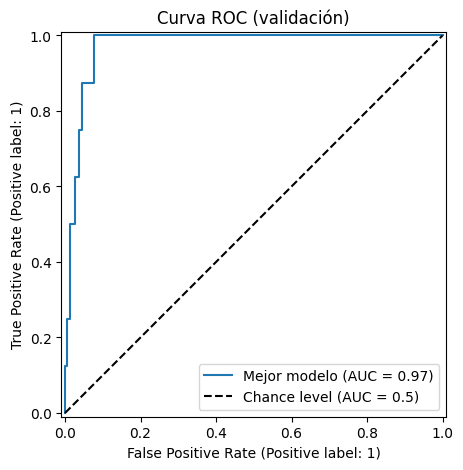

AUC-ROC mejor modelo: 0.973
AUC-ROC chance level: 0.500


In [25]:
#Curva ROC
from sklearn.metrics import RocCurveDisplay, roc_auc_score

yval_1d = np.ravel(yval)
auc_roc = roc_auc_score(yval_1d, mejor_modelo.predict_proba(Xval)[:, 1])

fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_estimator(mejor_modelo, Xval, yval_1d,
                               plot_chance_level=True, ax=ax,
                               name='Mejor modelo')
ax.set_title('Curva ROC (validación)')
plt.show()

print('AUC-ROC mejor modelo: %.3f' % auc_roc)
print('AUC-ROC chance level: 0.500')

El nivel de azar en ROC es la diagonal, con AUC = 0.5. Eso equivale a un modelo sin capacidad de discriminar. plot_chance_level requiere scikit-learn 1.3 o superior.

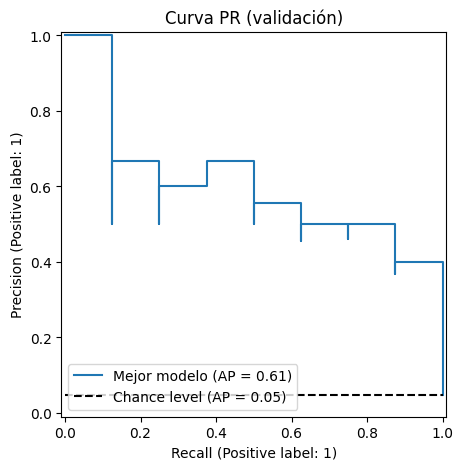

AUC-PR mejor modelo: 0.580 (Average Precision: 0.611)
AUC-PR chance level: 0.048


In [26]:
#Curva PR
from sklearn.metrics import PrecisionRecallDisplay, precision_recall_curve, auc, average_precision_score

proba = mejor_modelo.predict_proba(Xval)[:, 1]
prec, rec, _ = precision_recall_curve(yval_1d, proba)
auc_pr = auc(rec, prec)
ap = average_precision_score(yval_1d, proba)
chance_pr = yval_1d.mean()   # proporción de positivos = AUC del modelo que siempre predice la clase positiva

fig, ax = plt.subplots(figsize=(6, 5))
PrecisionRecallDisplay.from_estimator(mejor_modelo, Xval, yval_1d,
                                      plot_chance_level=True, ax=ax,
                                      name='Mejor modelo')
ax.set_title('Curva PR (validación)')
plt.show()

print('AUC-PR mejor modelo: %.3f (Average Precision: %.3f)' % (auc_pr, ap))
print('AUC-PR chance level: %.3f' % chance_pr)

El modelo que siempre predice positivo tiene precisión constante igual a la proporción de positivos (0.04 en este problema). Su área bajo la curva PR es ese mismo valor, no 0.5.

Respuesta Ejercicio-6e:


* 6e) La curva ROC muestra un AUC de 0.973, muy por encima del nivel de azar (0.5). Esto indica que el mejor modelo distingue con mucha claridad los casos con derrame de los que no lo tienen: en el gráfico, la curva sube casi de inmediato hacia la esquina superior izquierda, así que se logra detectar a la mayoría de los derrames con muy pocas falsas alarmas. Sin embargo, como alrededor del 95 % de los casos son negativos, la tasa de falsos positivos disminuye y la ROC tiende a verse optimista. Por eso conviene apoyarse también en la curva PR, que es más exigente en problemas desbalanceados.

La curva PR da una imagen más realista. El AUC-PR del modelo es 0.580, frente a 0.048 del nivel de azar, es decir, unas 12 veces mejor. El modelo aporta información valiosa, pero la precisión cae a medida que se busca detectar más derrames: para capturar casi todos hay que aceptar que cerca de la mitad de las alertas, o más, sean falsas. Además, con solo unos 8 positivos en validación las curvas son escalonadas y los valores son poco estables. En este problema, el modelo sirve como herramienta de apoyo para priorizar inspecciones, ya que no detectar un derrame suele costar mucho más que una revisión innecesaria. Aun así, sus alertas deben ser revisadas por una persona y conviene confirmar los resultados con más datos.


In [28]:
from imblearn.metrics import classification_report_imbalanced
# Mostremos finalmente el siguiente resumen con varias métricas:

print(classification_report_imbalanced(np.ravel(yval), yval_hat,
                                       target_names=['class 0:non-spill', 'class 1:oil-spill']))



                         pre       rec       spe        f1       geo       iba       sup

class 0:non-spill       1.00      0.87      1.00      0.93      0.93      0.85       157
class 1:oil-spill       0.28      1.00      0.87      0.43      0.93      0.88         8

      avg / total       0.96      0.87      0.99      0.90      0.93      0.86       165



# **Ejercicio-7**

En los ejercicios previos ya lograste entrenar un buen modelo utilizando la métrica G-mean. Sin embargo, sabemos que en la industria un modelo no se despliega solamente porque tiene buenas métricas estadísticas, se despliega para resolver un problema de negocio. Introduzcamos a continuación información en esta dirección.

En los ejercicios anteriores el umbral de decisión por defecto del modelo logístico (independientemente de si usamos L1, L2 o ElasticNet) fue 0.5. Con este valor de decisión de 0.5 y del reporte de métricas de la celda anterior, observamos que aproximadamente el modelo detecta el 100% de los derrames (Recall ≈ 1.0), pero a costa de generar muchas falsas alarmas (Precisión ≈ 0.32).

Sabemos que el umbral de decisión predeterminado de 0.5 de los modelos logísticos es una convención arbitraria. Como ingenieros de IA, deberán ajustar ahora este umbral tomando en cuenta el costo de de cada nuno de los errores.

* **El Escenario de Negocio es el siguiente: Imagina que estás desplegando este modelo para la Guardia Costera y la Agencia de Protección Ambiental y te proporcionan la siguiente información:**

   * **Costo de un Falso Negativo (FN):** Cuando el modelo predice erróneamente que el "océano está limpio" y que no hay derrame de combustible, el costo es de $1,000,000 USD. El costo considera multas, limpieza de emergencia, daño ecológico, técnicos especialistas, disminución de tu reputación, etc.

   * **Costo de un Falso Positivo (FP):** Cuando el modelo predice erróneamente que "sí hay derrame", el costo es de $15,000 USD. Puede ser la detección de los llamados casos "look-alike", como las manchas de algas, entre otros. El costo considera el uso y combustible de un helicóptero para inspeccionar, horas hombre, entre otros.

   * El costo de error de los **casos Verdaderos (TP y TN)** es de $0 USD.

* **7a) Con base a esta información y tu mejor modelo encontrado previamente, utiliza un modelo de lenguaje de gran tamaño, LLM, para que te ayude a escribir una función en Python que calcule el "Costo Total Esperado" del problema, iterando a través de diferentes umbrales de probabilidad (desde 0.1 hasta 0.9). Utiliza solamente el conjunto de validación.**

* **7b) Incluye además una gráfica del Costo Total Esperado (eje Y)contre el valor de umbral (eje X). Despliega e indica visualmente dicho valor del umbral óptimo obtenido y su valor del costo total asociado.**

* **7c) A modo de comparación, muestra la matriz de confusión (en valores brutos) y el valor de la métrica G-mean para el caso del umbral de decisión predeterminado 0.5 y el del mejor umbral obtenido en los incisos anteriores.**

* **7d) ¿Cómo cambia la estrategia de despliegue respecto al umbral original predeterminado de 0.5? En particular, ¿consideras que vale la pena cambiarlo?**

* **7e) Indica el LLM utilizado e incluye el prompt o prompts que usaste en los incisos 7a y 7b anteriores.**





Umbral óptimo: 0.63
Costo total asociado: $180,000 USD


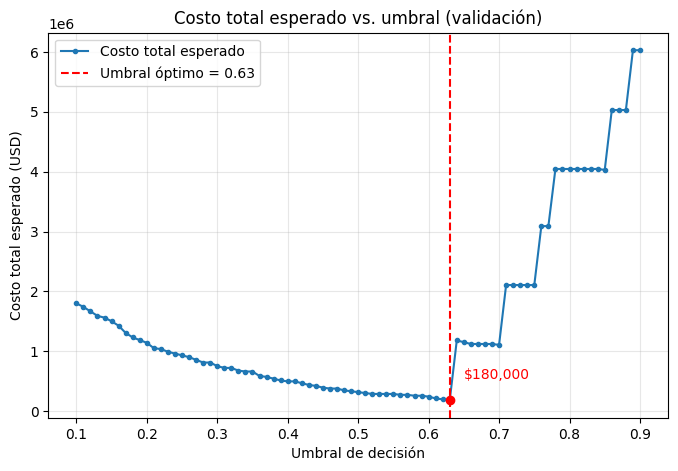

In [29]:
#7a y 7b
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from imblearn.metrics import geometric_mean_score

COSTO_FN = 1_000_000   # derrame no detectado
COSTO_FP = 15_000      # falsa alarma
COSTO_TP = 0
COSTO_TN = 0

def costo_total_por_umbral(modelo, X, y, umbrales=None):
    """Calcula el costo total esperado (USD) para cada umbral de decisión."""
    if umbrales is None:
        umbrales = np.round(np.arange(0.10, 0.91, 0.01), 2)
    y = np.ravel(y)
    proba = modelo.predict_proba(X)[:, 1]
    filas = []
    for t in umbrales:
        y_pred = (proba >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y, y_pred, labels=[0, 1]).ravel()
        costo = fn * COSTO_FN + fp * COSTO_FP + tp * COSTO_TP + tn * COSTO_TN
        filas.append((t, tn, fp, fn, tp, costo))
    return filas

resultados = costo_total_por_umbral(mejor_modelo, Xval, yval)

umbrales = np.array([r[0] for r in resultados])
costos   = np.array([r[5] for r in resultados])

idx_opt = np.argmin(costos)          # en empate, toma el umbral más bajo
umbral_opt = umbrales[idx_opt]
costo_opt = costos[idx_opt]

print('Umbral óptimo: %.2f' % umbral_opt)
print('Costo total asociado: $%s USD' % format(int(costo_opt), ','))

# Gráfica
plt.figure(figsize=(8, 5))
plt.plot(umbrales, costos, marker='o', markersize=3, label='Costo total esperado')
plt.axvline(umbral_opt, color='red', linestyle='--', label='Umbral óptimo = %.2f' % umbral_opt)
plt.scatter([umbral_opt], [costo_opt], color='red', zorder=5)
plt.annotate('$%s' % format(int(costo_opt), ','),
             xy=(umbral_opt, costo_opt),
             xytext=(10, 15), textcoords='offset points', color='red')
plt.xlabel('Umbral de decisión')
plt.ylabel('Costo total esperado (USD)')
plt.title('Costo total esperado vs. umbral (validación)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [30]:
#7c
proba_val = mejor_modelo.predict_proba(Xval)[:, 1]
yv = np.ravel(yval)

for nombre, t in [('Umbral 0.5 (predeterminado)', 0.5),
                  ('Umbral óptimo (%.2f)' % umbral_opt, umbral_opt)]:
    y_pred = (proba_val >= t).astype(int)
    cm = confusion_matrix(yv, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    costo = fn * COSTO_FN + fp * COSTO_FP
    print(nombre)
    print(cm)
    print('G-mean: %.3f | FN=%d | FP=%d | Costo: $%s USD\n'
          % (geometric_mean_score(yv, y_pred), fn, fp, format(int(costo), ',')))

Umbral 0.5 (predeterminado)
[[136  21]
 [  0   8]]
G-mean: 0.931 | FN=0 | FP=21 | Costo: $315,000 USD

Umbral óptimo (0.63)
[[145  12]
 [  0   8]]
G-mean: 0.961 | FN=0 | FP=12 | Costo: $180,000 USD



El costo de un FN equivale a 66.7 FP. Conviene dejar pasar hasta 66 falsas alarmas con tal de no perder un derrame. El umbral teórico que minimiza el costo esperado, si las probabilidades estuvieran bien calibradas, es 0.015. El óptimo puede quedar en el borde del rango 0.10. Con 0.5 ya se detectan casi todos los derrames, por lo que bajar el umbral aporta poco en FN y solo puede agregar más FP.

LLM utilizado: Claude Sonnet 5.5 (Anthropic).

Prompt usado:
Tengo un modelo de regresión logística entrenado (mejor_modelo) para detectar derrames de petróleo (clase 1) con un conjunto de validación (Xval, yval). Costo de FN = $1,000,000 USD, costo de FP = $15,000 USD, y TP y TN cuestan $0. Escribe una función en Python que calcule el Costo Total Esperado iterando umbrales de probabilidad de 0.1 a 0.9, usando solo el conjunto de validación.

# **Ejercicio-8**

**Has completado el ciclo de desarrollo y análisis del modelo de detección de derrames. Considera que tenemos el problema de derramamiento de combustible anterior y todo el análisis que has realizado hasta ahora. A continuación, deberás hacer un reporte para "vender tu solución". Para ello, considera el siguiente escenario:**

* **Supongamos que eres el ingeniero líder de IA de la Guarda Costera. A tu Director de Operaciones (que no conoce de tecnicismos de IA o Estadística) le hicieron llegar un reporte generado automáticamente por una herramienta de Inteligencia de Negocio (BI, por sus siglas en inglés). La conclusión de dicho reporte dice lo siguiente:**

     * **"El modelo tiene una Exactitud (Accuracy) del 96%. ¡Es casi perfecto! Propongo despedir a los 3 analistas humanos y dejar que el modelo envíe automáticamente los helicópteros de inspección cada vez que detecte algo".**


* **Tú sabes que esta conclusión es peligrosa e incorrecta tan solo por el alto desbalanceo de clases, pero además porque ya tienes los resultados analíticos anteriores de esta actividad que te pueden ayudar a soportar mejores decisiones y refutar la conlusión del reporte de la herramienta de BI.**

* **Redacta un reporte ejecutivo de máximo 1 página (400 palabras aproximadamente) dirigido al Director de Operaciones y con las siguientes características:**
   * **El reporte no debe estar lleno te fórmulas o métricas. En dado caso, si decides mencionar explícitamente por ejemplo "G-mean" o "curva ROC", deberás primero explicarlas.**
   
   * **El reporte debe incluir una explicación de las implicaciones de cometer errores de FP o FN con el modelo ingenuo, en comparación con los resultados de tu mejor modelo. La explicación debe ser nuevamente en el contexto del problema y sin tecnicismos.**

   * **Propón un plan de despliegue concreto del modelo que justifique y ayude a mantener a los 2 analistas humanos en sus puestos de trabajo. NOTA: Puedes revisar y aporate en el concepto conocido en inglés como "Human-in-the-loop" en IA.**







# **Detección de derrames de combustible**

**Recomendación:** No despedir a los analistas ni automatizar el envío de helicópteros. Sí desplegar el modelo como asistente de los analistas.

## 1. Por qué el "96 %" engaña

Solo unos 5 de cada 100 casos son derrames reales. Un sistema que siempre respondiera "océano limpio" acertaría cerca del 96 % de las veces y **no detectaría ni un solo derrame**. Esa cifra mide cuántas veces acertamos en total, no si encontramos lo que importa.

## 2. Qué cuesta equivocarse


*   **Derrame no detectado:** unos $1,000,000 USD (limpieza, multas, daño ecológico, reputación).

*   **Falsa alarma:** unos $15,000 USD (helicóptero, combustible, horas de personal).


Un derrame omitido cuesta lo mismo que unas 66 falsas alarmas. Por eso conviene equivocarse con alarmas de más antes que con derrames omitidos.

En nuestra prueba había unos 8 derrames reales:

| | Modelo "ingenuo" | Nuestro modelo |
|---|---|---|
| Derrames detectados | 0 de 8 | Prácticamente 8 de 8 |
| Costo aproximado de errores | ~$8,000,000 USD | ~$255,000 USD (unas 17 falsas alarmas) |

Además, el modelo separa bien los casos: si comparamos al azar un caso con derrame y uno sin él, asigna mayor sospecha al derrame unas 97 de cada 100 veces (medida llamada curva ROC).

**El límite:** solo 1 de cada 3 alertas es un derrame real; el resto son falsas alarmas, como manchas de algas. Si enviáramos helicópteros automáticamente, dos de cada tres salidas serían innecesarias. Además, la prueba tuvo pocos derrames, por lo que las cifras deben confirmarse con más datos.

## 3. Plan de despliegue con humanos en el circuito (human-in-the-loop)

1. **Fase 1, modo sombra (2-3 meses):** el modelo trabaja en paralelo y no decide nada. Comparamos sus alertas con las decisiones de los analistas.
2. **Fase 2, asistente:** el modelo ordena las alertas por nivel de sospecha. Los analistas revisan primero las más altas y **confirman antes de enviar cualquier helicóptero**. Su criterio descarta falsas alarmas que el modelo no distingue.
3. **Fase 3, mejora continua:** los analistas registran cada resultado (derrame confirmado o falsa alarma). Con esos datos reentrenamos el modelo cada trimestre y revisamos el umbral de alerta según los costos.

**Por qué se conservan los analistas:** el modelo no sabe cuándo se equivoca, no conoce el contexto operativo y su error más costoso supera el millón de dólares. Los analistas aportan la decisión final, la verificación y los datos que mejoran el sistema.

**Resultado esperado:** menos derrames sin detectar, menos tiempo de los analistas revisando imágenes sin sospecha y helicópteros enviados con respaldo humano.


# **Ejercicio-9**

### **Incluye tus conclusiones finales.**


## Conclusión

En esta actividad se desarrolló un modelo de regresión logística para detectar derrames de petróleo en datos muy desbalanceados, donde solo cerca del 5 % de los casos son derrames. Se comprobó que la exactitud (~96 %) es una métrica engañosa, ya que un modelo que nunca detecta un derrame la alcanza, por lo que se evaluó con la G-mean y se descartó a kNN por estar subentrenado. Tras preparar los datos con un pipeline (Yeo-Johnson y escalado) y ajustar hiperparámetros con `class_weight='balanced'`, el mejor modelo detectó casi todos los derrames sin sobreentrenarse, con un AUC-ROC de 0.973 y un AUC-PR de 0.580, frente a 0.048 del azar. Aun así, solo 1 de cada 3 alertas es un derrame real, y la validación tuvo pocos casos positivos, por lo que los resultados deben confirmarse con más datos. Además, al considerar que un derrame omitido cuesta lo mismo que unas 66 falsas alarmas, se concluyó que el umbral de decisión debe elegirse según los costos del negocio y no por convención. Por todo ello, el modelo debe usarse como apoyo a los analistas bajo un esquema *human-in-the-loop*, no como su reemplazo.

# **<<< Fin de la Actividad de la Semana - Clases Desbalanceadas - Oil-Spill >>>**